In [1]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np
import zipfile
import os

### Getting the zip file path, and then extracting the required TIFF files.

In [2]:
# Replace with the path to your downloaded Sentinel-1 .SAFE.zip file on your local machine
zip_path = r"<PATH_TO_SENTINEL1_SAFE_ZIP>"  # e.g., r"./S1A_IW_GRDH_1SDV_20260602T140038_20260602T140103_064791_0829DF_6CCF.SAFE.zip"

with zipfile.ZipFile(zip_path, 'r') as z:
    file_list = z.namelist()
    # print(*file_list, sep="\n")

tiff_files = [f for f in file_list if f.endswith('.tiff') and 'measurement' in f]

print(f"Total files inside package: {len(file_list)}")
print(f"\nFound the following radar measurement bands:")

for tiff in tiff_files:
    print(f" -> {os.path.basename(tiff)}")

Total files inside package: 26

Found the following radar measurement bands:
 -> s1a-iw-grd-vh-20260602t140038-20260602t140103-064791-0829df-002.tiff
 -> s1a-iw-grd-vv-20260602t140038-20260602t140103-064791-0829df-001.tiff


In [3]:
for tiff in tiff_files: print(tiff, '\n', '->', os.path.basename(tiff))

S1A_IW_GRDH_1SDV_20260602T140038_20260602T140103_064791_0829DF_6CCF.SAFE/measurement/s1a-iw-grd-vh-20260602t140038-20260602t140103-064791-0829df-002.tiff 
 -> s1a-iw-grd-vh-20260602t140038-20260602t140103-064791-0829df-002.tiff
S1A_IW_GRDH_1SDV_20260602T140038_20260602T140103_064791_0829DF_6CCF.SAFE/measurement/s1a-iw-grd-vv-20260602t140038-20260602t140103-064791-0829df-001.tiff 
 -> s1a-iw-grd-vv-20260602t140038-20260602t140103-064791-0829df-001.tiff


### Turning the TIFF file containing the VV polar band into a raster map.

Extracting s1a-iw-grd-vv-20260602t140038-20260602t140103-064791-0829df-001.tiff...
Extraction complete. Opening matrix with rasterio...
[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]
Total Matrix dimensions: 16710 rows x 25489 columns


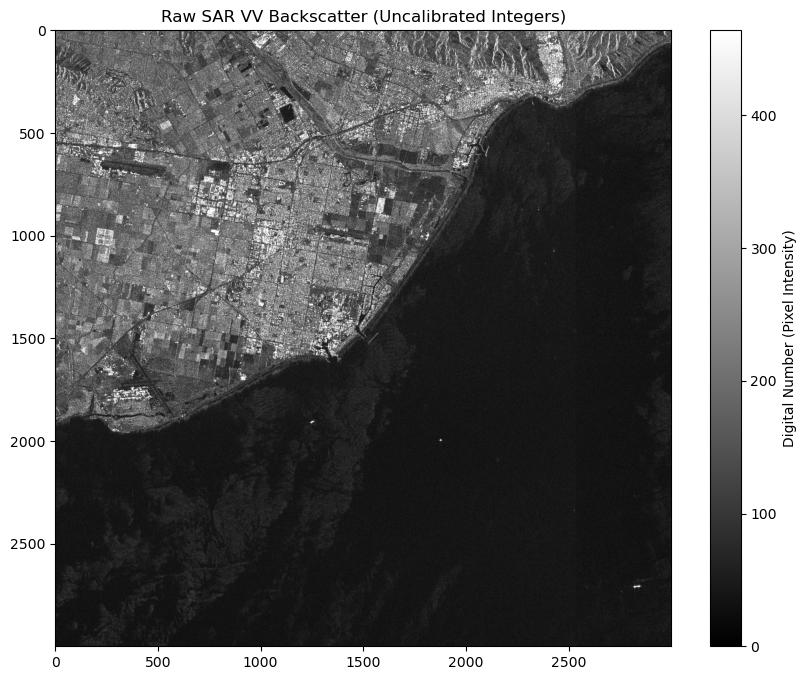

In [4]:
vv_filename = [f for f in tiff_files if '-vv-' in f][0]
print(f"Extracting {os.path.basename(vv_filename)}...")

with zipfile.ZipFile(zip_path, 'r') as z:
    extracted_path = z.extract(vv_filename, path=r"<PATH_TO_RAW_DATA_DIR>")  # e.g., r"./data_raw"
print(f"Extraction complete. Opening matrix with rasterio...")

with rasterio.open(extracted_path) as src:
    vv_array = src.read(1)
    print(vv_array[0:4142, 25192:25489]) # The coastline in the full image(downloaded from COPERNICUS) isn't perfectly diagonal like this- |/|, it rather is like this- |~|;
    # {{and as the data was captured during the satellite's ascent(S to N), the ocean is towards the top and the land part is towards the bottom of the image in contrast to the rendered image(here).
    # The image in the preview file of the zip folder is upright, whereas the metadata still has the upside-down matrix of the image.
    # [, 87] and [, 25192] are the limits starting from which the pixel values are zero(0, i.e., black) till the edges}}-this might be wrong...to be reconsidered.
    print(f"Total Matrix dimensions: {vv_array.shape[0]} rows x {vv_array.shape[1]} columns")

plt.figure(figsize=(10, 8))
subset = vv_array[7000:10000, 6000:9000] # the first ratio represents the latitudinal range(north-south or vice-versa) and the second ratio represents the longitudinal range(east-west or vice-versa)
vmax_cap = np.percentile(subset, 99)

plt.imshow(subset, cmap='gray', vmin=0, vmax=vmax_cap)
plt.title("Raw SAR VV Backscatter (Uncalibrated Integers)")
plt.colorbar(label="Digital Number (Pixel Intensity)")
# plt.show()

### Physics Calibration(converting digital numbers to decibel).

In [5]:
# 1. Convert to physical Backscatter (Sigma Naught approximation)
# We square the digital numbers to get intensity.
intensity = vv_array ** 2.0

# 2. Convert to Decibels (Logarithmic compression)
# The standard physics formula is 10 * log10(intensity)
db_array = 10 * np.log10(intensity + 1e-10) # We add a tiny number (1e-10) to prevent the math from crashing if there is a true 0 pixel.
# db = decibel, therefore db_array contains converted decibel values.

print("Calibration Complete.")
print(f"Old Range (Digital Numbers): Min {vv_array.min()} to Max {vv_array.max()}")
print(f"New Range (Decibels): Min {db_array.min():.2f} dB to Max {db_array.max():.2f} dB")

Calibration Complete.
Old Range (Digital Numbers): Min 0 to Max 65050
New Range (Decibels): Min -100.00 dB to Max 96.26 dB


### Speckle Filtering.

Hunting for valid satellite data...
Target locked! Valid data center is at Row: 9000, Col: 7500
Applying 7x7 Median Filter to the subset...


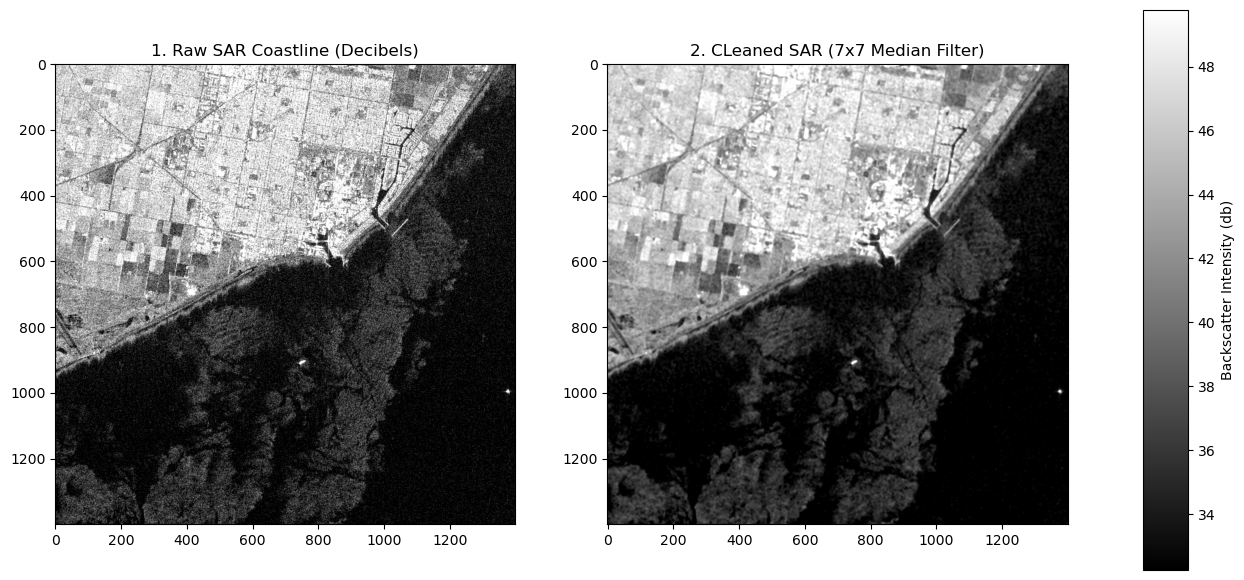

In [6]:
from scipy.ndimage import median_filter

# print("Hunting for valid satellite data...")
# valid_coords = np.where(vv_array > 0)
# center_y = int(np.median(valid_coords[0]))
# center_x = int(np.median(valid_coords[1]))
# print(f"Target locked! Valid data center is at Row: {center_y}, Col: {center_x}")

# slice_y = slice(center_y - 1000, center_y + 400)
# slice_x = slice(center_x - 1000, center_x + 400)
# raw_coast = db_array[slice_y, slice_x] # db = decibel, therefore db_array contains converted decibel values.

# The code, on its own, should find the "center pixel" from where it can span the coordinates for the image snippet to be processed, just like in the code above;
# for now the above code is choosing improper coordinates for the "center pixel" and therefore has been commented, for the method has to be changed.
# The code below has manually entered, deliberated coordinates to represent what an ideal code-generated image snippet should look like.
print("Hunting for valid satellite data...")
center_y = 9000
center_x = 7500
print(f"Target locked! Valid data center is at Row: {center_y}, Col: {center_x}")

slice_y = slice(center_y - 1000, center_y + 400)
slice_x = slice(center_x - 1000, center_x + 400)
raw_coast = db_array[slice_y, slice_x]


print("Applying 7x7 Median Filter to the subset...")
clean_coast = median_filter(raw_coast, size=7)

vmin_val = np.percentile(clean_coast, 20)
vmax_val = np.percentile(clean_coast, 98)

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
im1 = axes[0].imshow(raw_coast, cmap='gray', vmin=vmin_val, vmax=vmax_val)
axes[0].set_title("1. Raw SAR Coastline (Decibels)")
im2 = axes[1].imshow(clean_coast, cmap='gray', vmin=vmin_val, vmax=vmax_val)
axes[1].set_title("2. CLeaned SAR (7x7 Median Filter)")

fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.85, 0.15, 0.03, 0.7])
fig.colorbar(im2, cax=cbar_ax, label="Backscatter Intensity (db)")
# plt.show()



# print("Applying 5x5 Median Speckle Filter to the full matrix... (This might take 5-10 seconds)")
# filtered_db = median_filter(db_array, size=5)
# print("Filtering Complete")

# coast_slice_y = slice(4000, 6000)
# coast_slice_x = slice(2000, 4000)

# raw_coast = db_array[coast_slice_y, coast_slice_x]
# clean_coast = filtered_db[coast_slice_y, coast_slice_x]

# fig, axes = plt.subplots(1, 2, figsize=(15, 8))

# im1 = axes[0].imshow(raw_coast, cmap='gray', vmin=-25, vmax=0)
# axes[0].set_title("1. Raw SAR Coastline (Decibels)")

# im2 = axes[1].imshow(clean_coast, cmap='gray', vmin=-25, vmax=0)
# axes[1].set_title("1. Cleaned SAR Coastline (Median Filter)")

# fig.subplots_adjust(right=0.8)
# cbar_ax = fig.add_axes([0.85, 0.15, 0.03, 0.7])
# fig.colorbar(im2, cax=cbar_ax, label="Backscatter Intensity (db)")
# plt.show

In [9]:
# 1. Define a large 4096 x 4096 Region of Interest (ROI) around our coast
roi_size = 4096
half_size = roi_size // 2

# Calculate the boundaries ensuring we don't go off the edge of the matrix
start_y = max(0, center_y - half_size)
end_y = start_y + roi_size
start_x = max(0, center_x - half_size)
end_x = start_x + roi_size

print(f"Extracting a {roi_size}x{roi_size} region...")
roi_db = db_array[start_y:end_y, start_x:end_x]

# 2. Clean the noise from this large chunk (Takes ~10-20 seconds)
print("Applying Median Filter to the region...")
roi_filtered = median_filter(roi_db, size=7) # size changed from 5 to 7.

# 3. Normalize the scientific Data (-25 dB to +5 dB) into Image Data (0 to 255)
print("Normalizing to 8-bit image format...")
# DYNAMIC CALIBRATION FIX: Grab the actual 2nd and 98th percentiles of your specific data
min_db = np.percentile(roi_filtered, 2)
print(f"min_db = {min_db}")
max_db = np.percentile(roi_filtered, 98)
print(f"max_db = {max_db}")
roi_clipped = np.clip(roi_filtered, min_db, max_db)
print(f"roi_clipped = {roi_clipped}")

# Scale math: shift it above 0, divide by the range, multiply by 255
roi_normalized = ((roi_clipped - min_db) / (max_db - min_db)) * 255.0
roi_uint8 = roi_normalized.astype(np.uint8)
print(f"roi_uint8 = {roi_uint8}")

# 4. Create the output directory on your hard drive
sar_tiles_output_dir = r"<PATH_TO_SAR_TILES_OUTPUT_DIR>"  # e.g., r"./data_processed/sar_tiles"
output_dir = sar_tiles_output_dir
os.makedirs(sar_tiles_output_dir, exist_ok=True)

# 5. The Cookie Cutter Loop
print("Slicing into 256x256 tiles...")
tile_size = 256
tile_count = 0

for y in range(0, roi_size, tile_size):
    for x in range(0, roi_size, tile_size):
        
        # Cut the 256x256 tile
        tile = roi_uint8[y:y+tile_size, x:x+tile_size]
        
        # Failsafe: Make sure the tile is exactly 256x256 (in case of edge clipping)
        if tile.shape[0] == tile_size and tile.shape[1] == tile_size:
            
            # Failsafe: Ensure the tile actually contains data (ignore pure black padding)
            if np.mean(tile) > 5:
                
                # Save the tile as a PNG image
                filename = os.path.join(output_dir, f"tile_{tile_count:04d}.png")
                plt.imsave(filename, tile, cmap='gray', vmin=0, vmax=255)
                tile_count += 1

print(f"\nSUCCESS! Generated {tile_count} training tiles in the data_processed/sar_tiles folder.")

Extracting a 4096x4096 region...
Applying Median Filter to the region...
Normalizing to 8-bit image format...
min_db = 29.827233876685906
max_db = 48.9741263981016
roi_clipped = [[47.23455672 47.00496037 46.52671722 ... 32.25567713 32.25567713
  32.25567713]
 [47.23455672 47.23455672 47.23455672 ... 32.86905353 32.86905353
  32.86905353]
 [47.23455672 47.23455672 47.15869694 ... 32.25567713 32.86905353
  32.86905353]
 ...
 [35.98681099 35.84783379 35.84783379 ... 30.62957834 30.62957834
  30.62957834]
 [35.98681099 35.84783379 35.84783379 ... 30.88136089 30.88136089
  30.88136089]
 [35.98681099 35.84783379 35.84783379 ... 30.88136089 30.88136089
  30.88136089]]
roi_uint8 = [[231 228 222 ...  32  32  32]
 [231 231 231 ...  40  40  40]
 [231 231 230 ...  32  40  40]
 ...
 [ 82  80  80 ...  10  10  10]
 [ 82  80  80 ...  14  14  14]
 [ 82  80  80 ...  14  14  14]]
Slicing into 256x256 tiles...

SUCCESS! Generated 256 training tiles in the data_processed/sar_tiles folder.


In [11]:
import glob
import random
from skimage.filters import threshold_otsu

In [17]:
# 1. Setup Input and Output directories
masks_input_dir = r"<PATH_TO_SAR_TILES_DIR>"  # e.g., r"./data_processed/sar_tiles"
masks_output_dir = r"<PATH_TO_MASKS_OUTPUT_DIR>"  # e.g., r"./data_processed/masks"
os.makedirs(masks_output_dir, exist_ok=True)

# Grab all the PNG tiles we just made
tile_files = sorted(glob.glob(os.path.join(masks_input_dir, "*.png")))
print(f"Random tile_file element: {tile_files[random.randint(0, 256)]}")
print(f"Found {len(tile_files)} tiles. Generating Ground Truth Masks...")

processed_count = 0

for tile_path in tile_files:
    # 2. Read the image (convert to grayscale just in case)
    tile = plt.imread(tile_path)
    if tile.ndim == 3:
        tile = tile[:, :, 0] # Grab just one channel if it loaded as RGB; in this case, the 'Red' channel present at index zero(0).
        
    # Skip tiles that are purely one color (e.g., solid black ocean or solid white padding)
    # Otsu's method fails if there are no two distinct classes (land AND water)
    if np.var(tile) < 0.001:
        continue
        
    try:
        # 3. Calculate Otsu's Threshold
        thresh = threshold_otsu(tile)
        
        # 4. Create the Binary Mask (Water is dark, so pixels BELOW threshold become 1/255)
        # We save as 255 (White) for Land and 0 (Black) for Water
        binary_mask = tile > thresh
        mask_uint8 = (binary_mask * 255).astype(np.uint8)
        
        # 5. Save the Mask with the exact same filename
        filename = os.path.basename(tile_path)
        save_path = os.path.join(masks_output_dir, filename)
        
        plt.imsave(save_path, mask_uint8, cmap='gray', vmin=0, vmax=255)
        processed_count += 1
        
    except ValueError:
        # Happens if the tile is completely uniform
        continue

print(f"\nSUCCESS! Generated {processed_count} binary masks in data_processed/masks/")

Random tile_file element: ./data_processed/sar_tiles\tile_0117.png
Found 256 tiles. Generating Ground Truth Masks...

SUCCESS! Generated 256 binary masks in data_processed/masks/


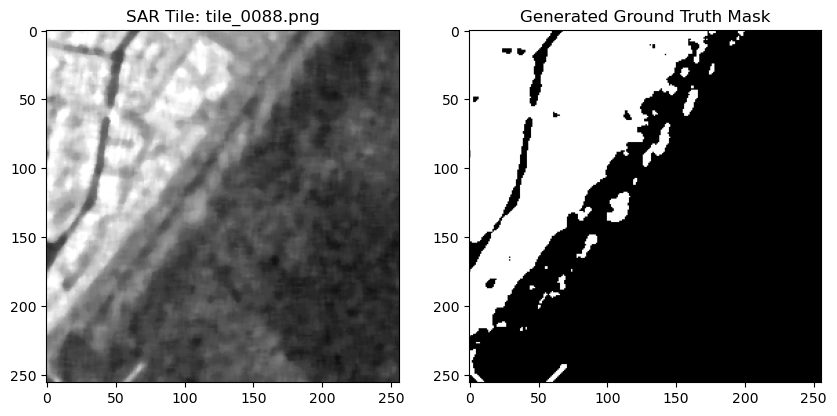

In [60]:
# 6. Let's visualize a random pair to make sure it worked!
import random
if processed_count > 0:
    test_file = random.choice(os.listdir(masks_output_dir))
    
    img_test = plt.imread(os.path.join(masks_input_dir, test_file))
    mask_test = plt.imread(os.path.join(masks_output_dir, test_file))
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img_test, cmap='gray')
    axes[0].set_title(f"SAR Tile: {test_file}")
    
    axes[1].imshow(mask_test, cmap='gray')
    axes[1].set_title("Generated Ground Truth Mask")
    plt.show()